In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Display charts inside Jupyter Notebook
%matplotlib inline

# Chart display size
plt.rcParams["figure.figsize"] = (10, 6)

# Chart style
plt.style.use("ggplot")

In [8]:
df = pd.read_excel("retail_sales_raw_10000_rows (1).xlsx")

df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,City,Sales_Channel,Category,Sub_Category,Product,Quantity,Unit_Price_INR,Discount,Sales_INR,Profit_INR,Payment_Mode,Order_Status,Ship_Days,Discount_Cleaned
0,ORD-100001,2025-07-12,CUST-01729,Aarav Sharma,West,Mumbai,Online,Clothing,Women,Kurti,1.0,779.08,0.00,779.08,169.05,UPI,Delivered,9.0,0.00
1,ORD-100002,2025-08-26,CUST-00027,Rohan Verma,Central,Indore,Phone Order,Furniture,Storage,Bookshelf,3.0,6849.54,0.15,17466.33,4189.21,Debit Card,Delivered,4.0,0.15
2,ORD-100003,2024-02-14,CUST-02197,Priya Patil,South,Bengaluru,Phone Order,Electronics,Accessories,Headphones,2.0,2602.59,0.10,4684.66,722.90,UPI,Delivered,11.0,0.10
3,ORD-100004,2024-03-22,CUST-00414,Rahul Gupta,Central,Raipur,Marketplace,Furniture,Storage,Bookshelf,3.0,2129.94,0.05,6070.33,882.30,Cash,Delivered,6.0,0.05
4,ORD-100005,2025-09-15,CUST-00701,Vikram Rao,North,Lucknow,Retail Store,Home & Kitchen,Cookware,Pressure Cooker,1.0,1594.14,0.25,1195.61,-38.91,Credit Card,Delivered,5.0,0.25


In [9]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

df["Order_Date"].dtype

dtype('<M8[us]')

In [10]:
monthly_sales = (
    df.dropna(subset=["Order_Date"])
      .set_index("Order_Date")
      .resample("MS")["Sales_INR"]
      .sum()
)

monthly_sales

Order_Date
2024-01-01     5774641.28
2024-02-01     8191746.37
2024-03-01     9777675.82
2024-04-01     9621302.15
2024-05-01     7293642.04
2024-06-01     9024259.40
2024-07-01     7149217.54
2024-08-01     8878792.45
2024-09-01     8264979.96
2024-10-01     8597642.26
2024-11-01     9162783.12
2024-12-01    10422537.57
2025-01-01    10654323.67
2025-02-01     8014587.31
2025-03-01     7919688.27
2025-04-01     8038029.60
2025-05-01     8332935.27
2025-06-01     7701304.94
2025-07-01     8663378.57
2025-08-01     7918223.41
2025-09-01     7573552.68
2025-10-01    10224036.21
2025-11-01     7707905.94
Freq: MS, Name: Sales_INR, dtype: float64

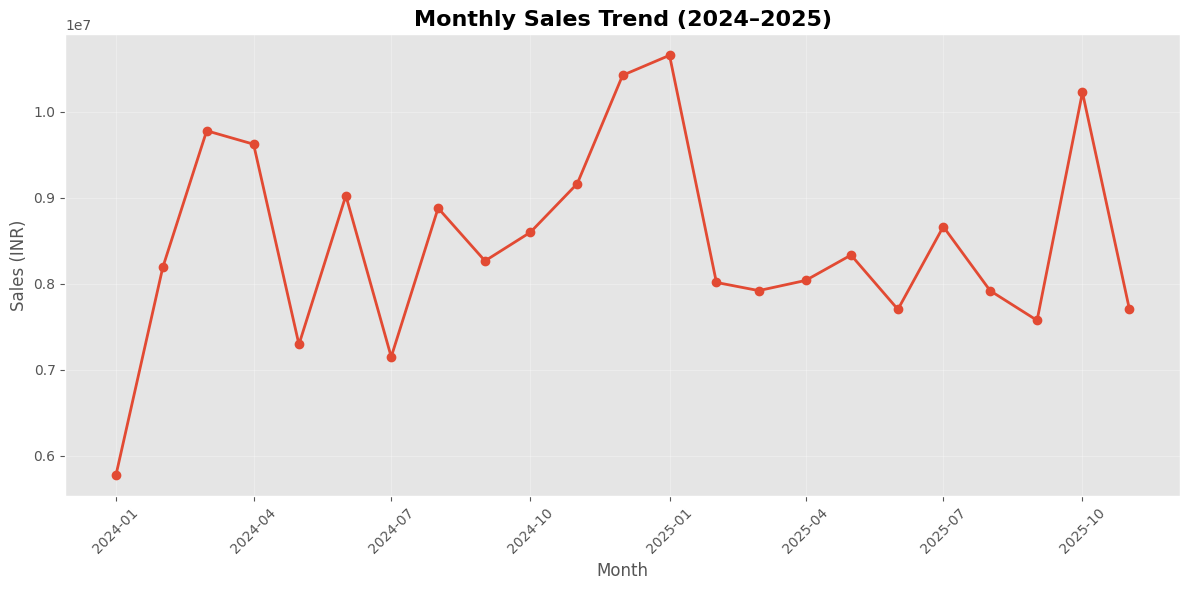

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2,
    markersize=6
)

plt.title("Monthly Sales Trend (2024–2025)",
          fontsize=16, fontweight="bold")

plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales (INR)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

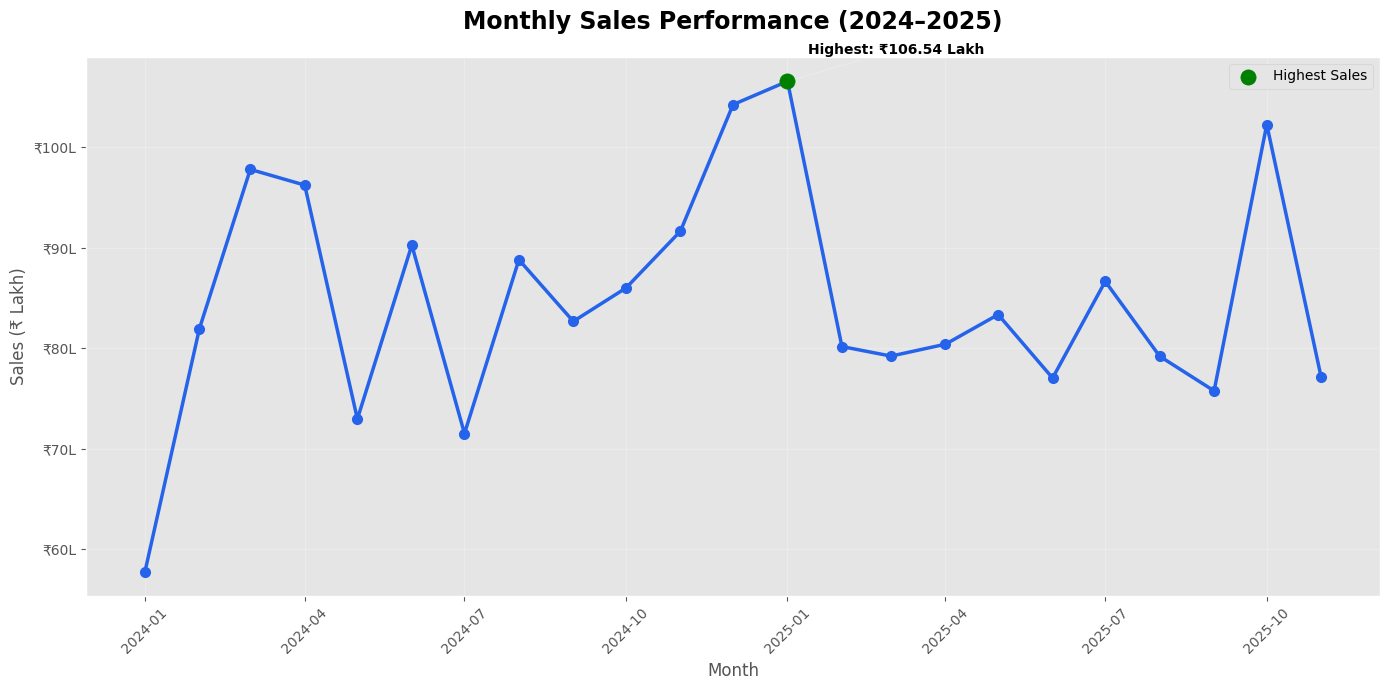

In [12]:
plt.figure(figsize=(14, 7))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#2563EB"
)

# Highest sales point
max_month = monthly_sales.idxmax()
max_sales = monthly_sales.max()

plt.scatter(
    max_month,
    max_sales,
    color="green",
    s=120,
    zorder=5,
    label="Highest Sales"
)

# Highlight highest sales
plt.annotate(
    f"Highest: ₹{max_sales/100000:.2f} Lakh",
    xy=(max_month, max_sales),
    xytext=(15, 20),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->")
)

plt.title(
    "Monthly Sales Performance (2024–2025)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales (₹ Lakh)", fontsize=12)

# Convert Y-axis into Lakhs
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/100000:.0f}L")
)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
category_sales = (
    df.groupby("Category")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

category_sales

Category
Electronics       1.447179e+08
Furniture         3.045907e+07
Home & Kitchen    1.091142e+07
Clothing          7.226118e+06
Beauty            4.589584e+06
Name: Sales_INR, dtype: float64

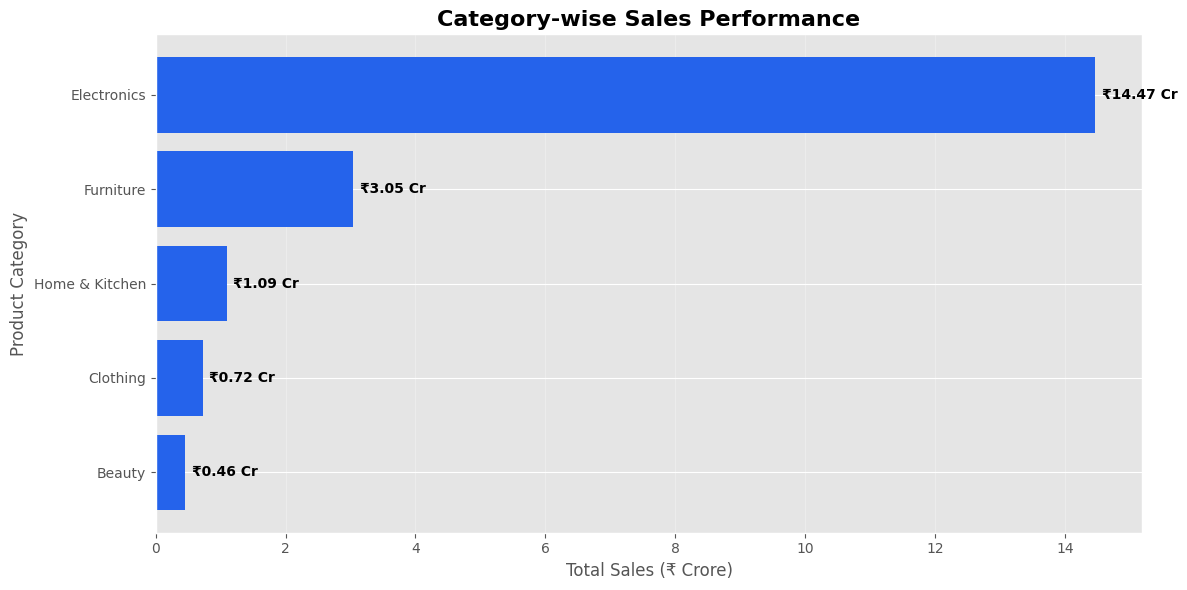

In [14]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    category_sales.index,
    category_sales.values / 10000000,
    color="#2563EB"
)

# Highest sales on top
plt.gca().invert_yaxis()

# Add data labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.1,
        bar.get_y() + bar.get_height()/2,
        f"₹{width:.2f} Cr",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Category-wise Sales Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Sales (₹ Crore)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
region_sales = (
    df.groupby("Region")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

region_sales

Region
East        41352941.73
South       39429688.98
Central     38637377.42
North       38252419.99
West        35974081.44
EAST         1297629.62
 west        1009823.54
south         828577.45
NORTH         708480.47
 central      413112.82
Name: Sales_INR, dtype: float64

In [16]:
df["Region"] = (
    df["Region"]
    .str.strip()
    .str.title()
)

In [17]:
region_sales = (
    df.groupby("Region")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

region_sales

Region
East       42650571.35
South      40258266.43
Central    39050490.24
North      38960900.46
West       36983904.98
Name: Sales_INR, dtype: float64

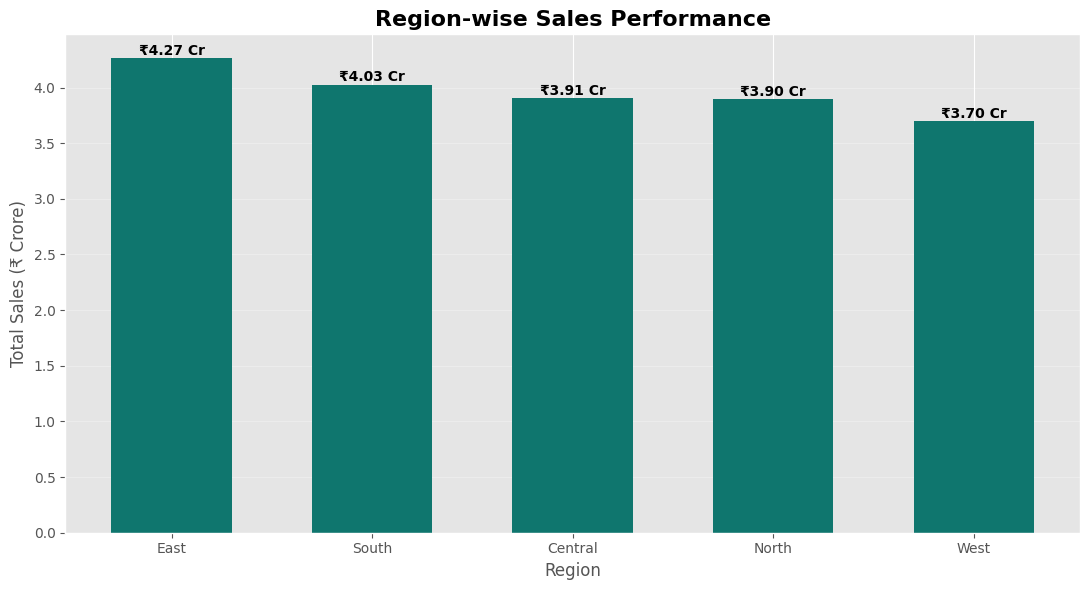

In [18]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    region_sales.index,
    region_sales.values / 10000000,
    color="#0F766E",
    width=0.6
)

# Add sales labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.03,
        f"₹{height:.2f} Cr",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Region-wise Sales Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Region")
plt.ylabel("Total Sales (₹ Crore)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
channel_sales = (
    df.groupby("Sales_Channel")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

channel_sales

Sales_Channel
Online           50965919.98
Retail Store     50366898.71
Phone Order      50107382.45
Marketplace      44215853.99
Retail store       996472.91
online             642987.18
 MARKETPLACE       608618.24
Name: Sales_INR, dtype: float64

In [20]:
df["Sales_Channel"] = (
    df["Sales_Channel"]
    .str.strip()
    .str.title()
)

In [21]:
channel_sales = (
    df.groupby("Sales_Channel")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

channel_sales

Sales_Channel
Online          51608907.16
Retail Store    51363371.62
Phone Order     50107382.45
Marketplace     44824472.23
Name: Sales_INR, dtype: float64

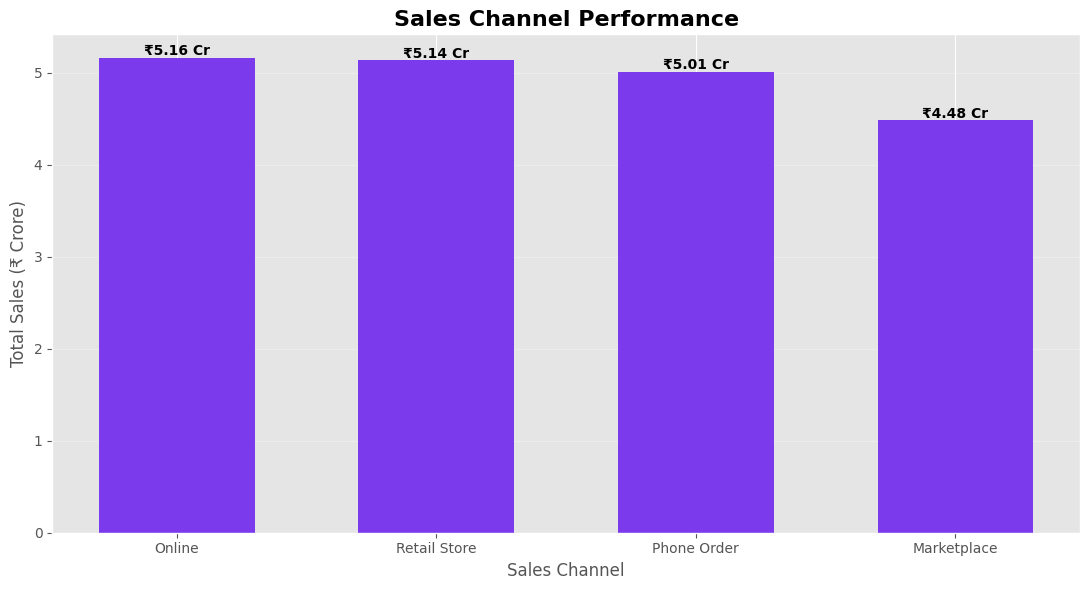

In [22]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    channel_sales.index,
    channel_sales.values / 10000000,
    color="#7C3AED",
    width=0.6
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.03,
        f"₹{height:.2f} Cr",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Sales Channel Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sales Channel")
plt.ylabel("Total Sales (₹ Crore)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
category_profit = (
    df.groupby("Category")["Profit_INR"]
      .sum()
      .sort_values(ascending=False)
)

category_profit

Category
Electronics       20328190.91
Furniture          4504056.49
Home & Kitchen     1461466.08
Clothing           1024539.88
Beauty              650377.71
Name: Profit_INR, dtype: float64

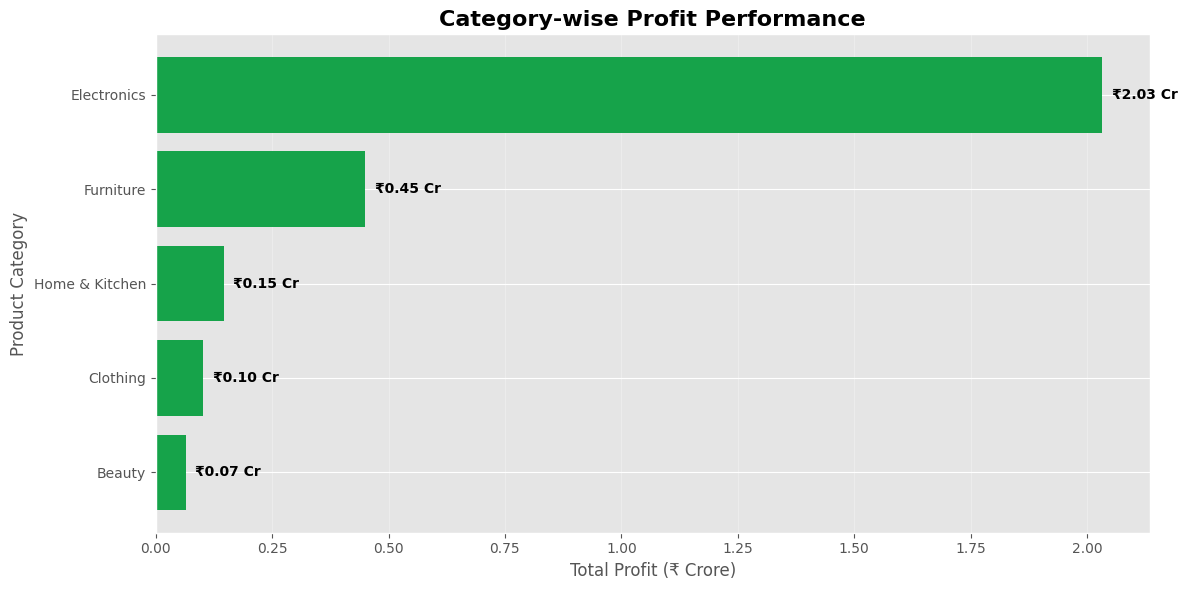

In [24]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    category_profit.index,
    category_profit.values / 10000000,
    color="#16A34A"
)

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"₹{width:.2f} Cr",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Category-wise Profit Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Profit (₹ Crore)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
category_margin = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales_INR", "sum"),
          Total_Profit=("Profit_INR", "sum")
      )
)

category_margin["Profit_Margin_%"] = (
    category_margin["Total_Profit"] /
    category_margin["Total_Sales"]
) * 100

category_margin = category_margin.sort_values(
    "Profit_Margin_%",
    ascending=False
)

category_margin

,Total_Sales,Total_Profit,Profit_Margin_%
Category,,,
Furniture,3.045907e+07,4504056.49,14.787242
Clothing,7.226118e+06,1024539.88,14.178288
Beauty,4.589584e+06,650377.71,14.170735
Electronics,1.447179e+08,20328190.91,14.046766
Home & Kitchen,1.091142e+07,1461466.08,13.393915


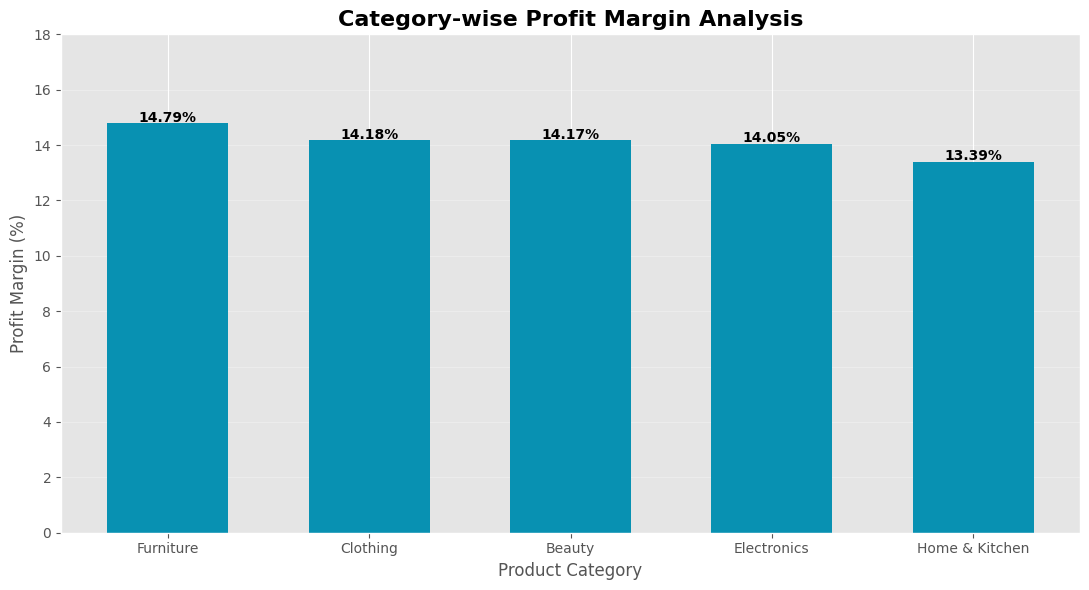

In [26]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    category_margin.index,
    category_margin["Profit_Margin_%"],
    color="#0891B2",
    width=0.6
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Category-wise Profit Margin Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Profit Margin (%)")

plt.ylim(0, 18)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
top_customers = (
    df.groupby("Customer_Name")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_customers

Customer_Name
Neha Kulkarni    18253809.27
Ananya Singh     18061959.61
Rahul Gupta      17717799.24
Vikram Rao       17451471.41
Sneha Joshi      16991149.42
Aditya Shah      16150237.70
Priya Patil      15963547.77
Pooja Nair       15567922.26
Aarav Sharma     15376084.35
Isha Mehta       15361586.33
Name: Sales_INR, dtype: float64

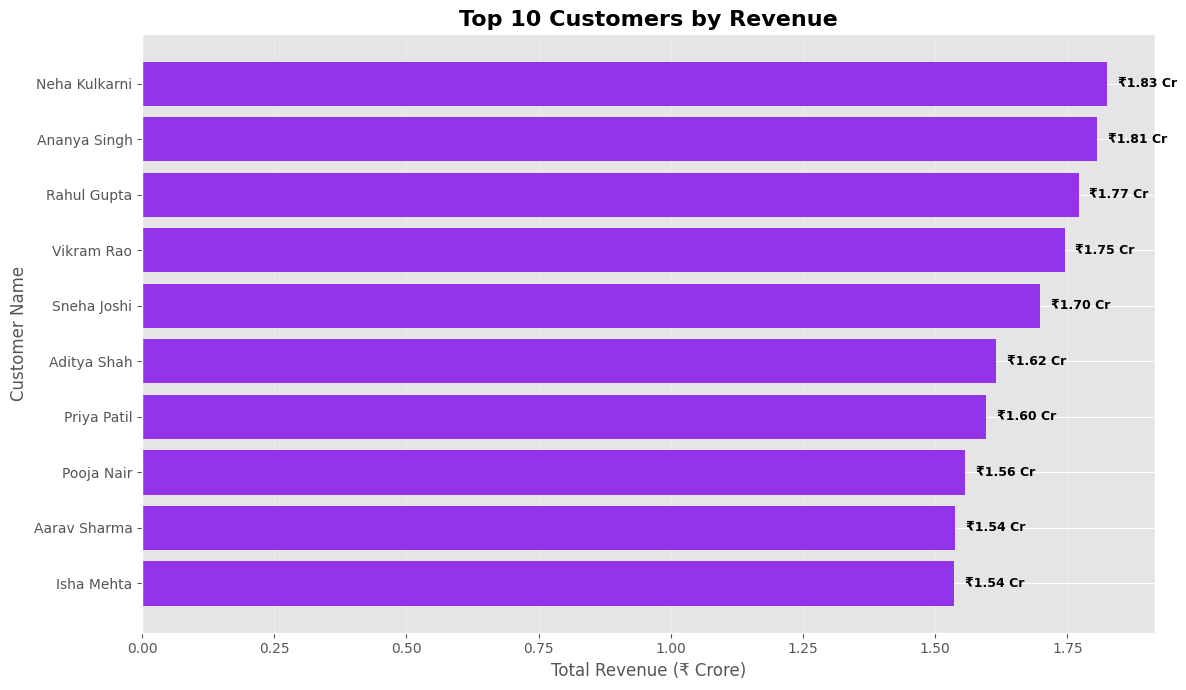

In [28]:
plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_customers.index,
    top_customers.values / 10000000,
    color="#9333EA"
)

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"₹{width:.2f} Cr",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title(
    "Top 10 Customers by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Revenue (₹ Crore)")
plt.ylabel("Customer Name")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
total_sales = df["Sales_INR"].sum()

top_10_sales = top_customers.sum()

top_10_contribution = (
    top_10_sales / total_sales
) * 100

print("Total Business Sales:", round(total_sales, 2))

print("Top 10 Customer Sales:", round(top_10_sales, 2))

print("Top 10 Customer Contribution:",
      round(top_10_contribution, 2), "%")

Total Business Sales: 197904133.46
Top 10 Customer Sales: 166895567.36
Top 10 Customer Contribution: 84.33 %


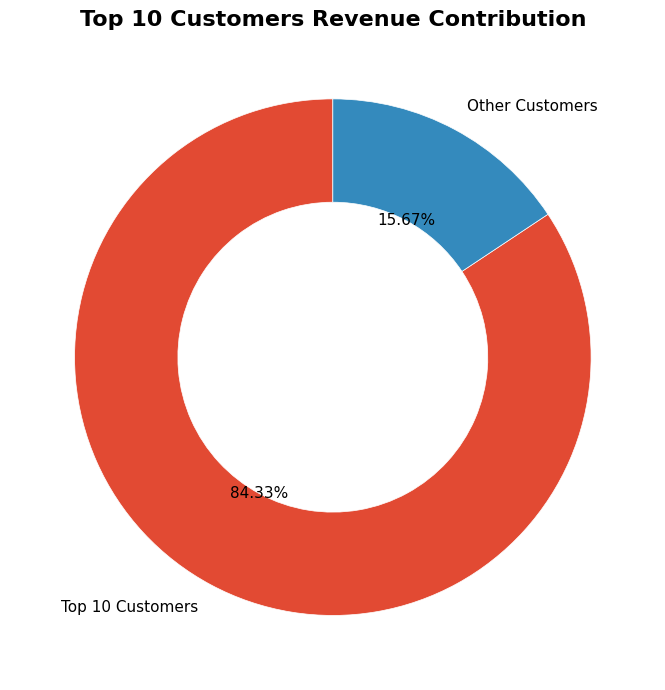

In [30]:
other_customers_sales = total_sales - top_10_sales

labels = ["Top 10 Customers", "Other Customers"]

values = [top_10_sales, other_customers_sales]

plt.figure(figsize=(9, 7))

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 11}
)

plt.title(
    "Top 10 Customers Revenue Contribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [31]:
order_status = df["Order_Status"].value_counts()

order_status

Order_Status
Delivered    7727
Cancelled     910
Returned      863
Pending       476
Name: count, dtype: int64

In [32]:
order_status_percentage = (
    df["Order_Status"]
    .value_counts(normalize=True) * 100
)

order_status_percentage.round(2)

Order_Status
Delivered    77.46
Cancelled     9.12
Returned      8.65
Pending       4.77
Name: proportion, dtype: float64

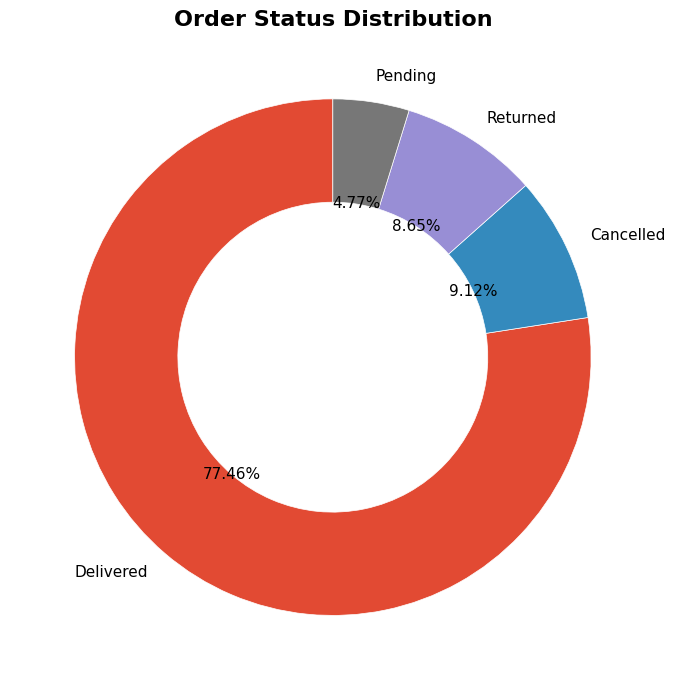

In [33]:
plt.figure(figsize=(9, 7))

plt.pie(
    order_status.values,
    labels=order_status.index,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={
        "width": 0.4,
        "edgecolor": "white"
    },
    textprops={"fontsize": 11}
)

plt.title(
    "Order Status Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [34]:
payment_sales = (
    df.groupby("Payment_Mode")["Sales_INR"]
      .sum()
      .sort_values(ascending=False)
)

payment_sales

Payment_Mode
UPI            36177653.92
Debit Card     33769154.18
Wallet         33649770.61
Cash           31578751.02
Credit Card    31497183.97
Net Banking    30703415.87
Unknown          528203.89
Name: Sales_INR, dtype: float64

In [35]:
payment_orders = (
    df["Payment_Mode"]
    .value_counts()
)

payment_orders

Payment_Mode
Wallet         1690
UPI            1686
Cash           1664
Net Banking    1642
Debit Card     1635
Credit Card    1619
Unknown          40
Name: count, dtype: int64

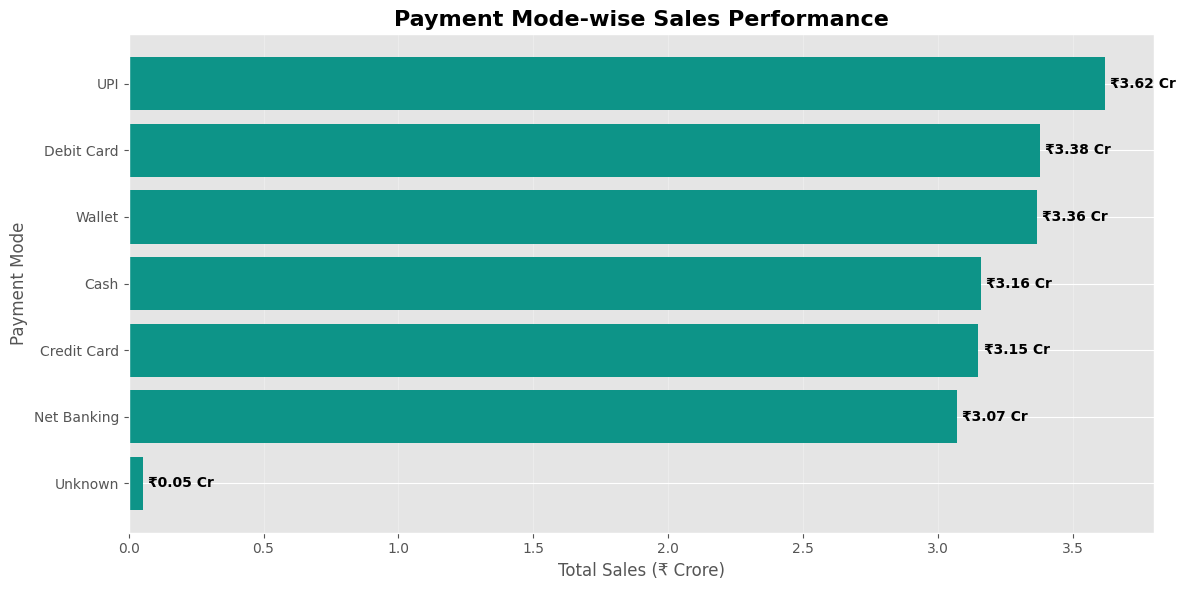

In [36]:
plt.figure(figsize=(12, 6))

bars = plt.barh(
    payment_sales.index,
    payment_sales.values / 10000000,
    color="#0D9488"
)

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"₹{width:.2f} Cr",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Payment Mode-wise Sales Performance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Sales (₹ Crore)")
plt.ylabel("Payment Mode")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

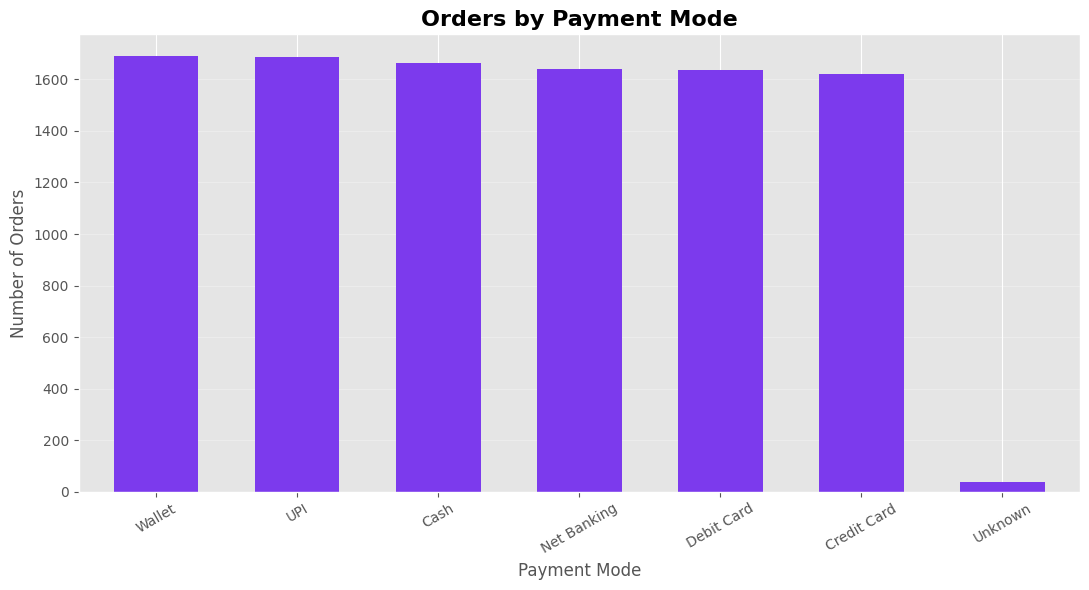

In [37]:
plt.figure(figsize=(11, 6))

payment_orders.plot(
    kind="bar",
    color="#7C3AED",
    width=0.6
)

plt.title(
    "Orders by Payment Mode",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
total_orders = df["Order_ID"].nunique()

total_revenue = df["Sales_INR"].sum()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)

print("Total Revenue:", round(total_revenue, 2))

print("Average Order Value:", round(average_order_value, 2))

Total Orders: 9975
Total Revenue: 197904133.46
Average Order Value: 19840.01


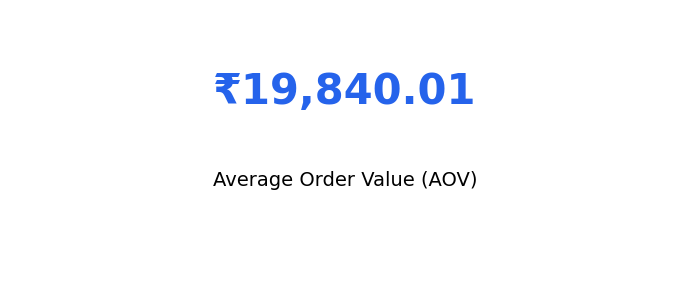

In [39]:
fig, ax = plt.subplots(figsize=(7, 3))

ax.text(
    0.5, 0.65,
    f"₹{average_order_value:,.2f}",
    fontsize=30,
    fontweight="bold",
    color="#2563EB",
    ha="center"
)

ax.text(
    0.5, 0.35,
    "Average Order Value (AOV)",
    fontsize=14,
    ha="center"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [40]:
# Business KPIs

total_sales = df["Sales_INR"].sum()

total_profit = df["Profit_INR"].sum()

total_orders = df["Order_ID"].nunique()

average_order_value = total_sales / total_orders

profit_margin = (total_profit / total_sales) * 100

total_customers = df["Customer_ID"].nunique()

# Display KPIs

print("========== SALES ANALYTICS KPI SUMMARY ==========")

print(f"Total Sales       : ₹{total_sales:,.2f}")
print(f"Total Profit      : ₹{total_profit:,.2f}")
print(f"Total Orders      : {total_orders:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Profit Margin     : {profit_margin:.2f}%")
print(f"Total Customers   : {total_customers:,}")

========== SALES ANALYTICS KPI SUMMARY ==========
Total Sales       : ₹197,904,133.46
Total Profit      : ₹27,968,631.07
Total Orders      : 9,975
Average Order Value: ₹19,840.01
Profit Margin     : 14.13%
Total Customers   : 2,175


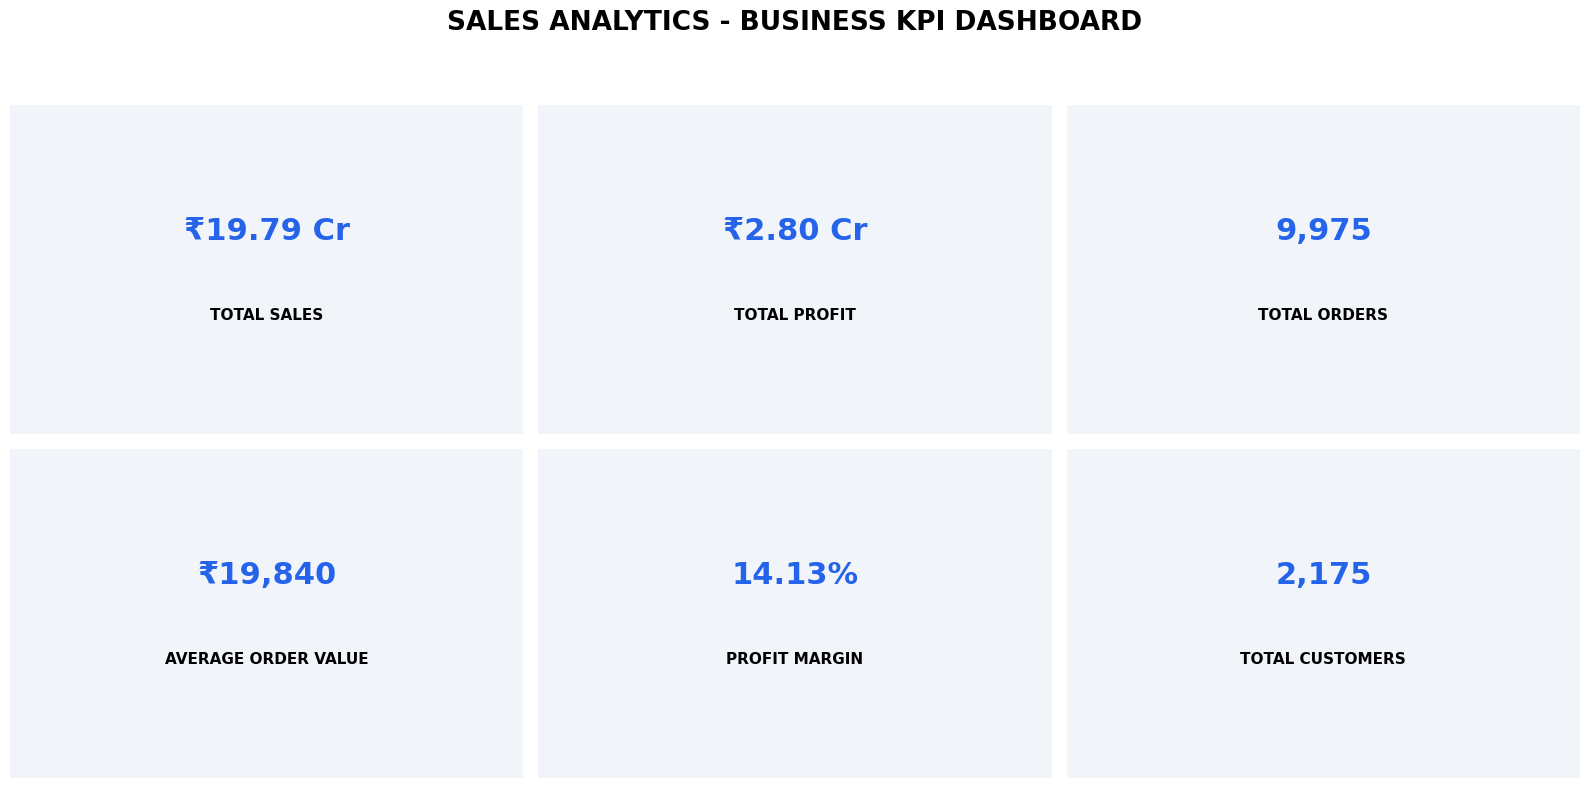

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

kpis = [
    ("TOTAL SALES", f"₹{total_sales/10000000:.2f} Cr"),
    ("TOTAL PROFIT", f"₹{total_profit/10000000:.2f} Cr"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("AVERAGE ORDER VALUE", f"₹{average_order_value:,.0f}"),
    ("PROFIT MARGIN", f"{profit_margin:.2f}%"),
    ("TOTAL CUSTOMERS", f"{total_customers:,}")
]

for ax, (title, value) in zip(axes.flat, kpis):

    ax.text(
        0.5, 0.62, value,
        fontsize=22,
        fontweight="bold",
        color="#2563EB",
        ha="center",
        va="center"
    )

    ax.text(
        0.5, 0.35, title,
        fontsize=11,
        fontweight="bold",
        ha="center"
    )

    ax.set_facecolor("#F1F5F9")
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "SALES ANALYTICS - BUSINESS KPI DASHBOARD",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

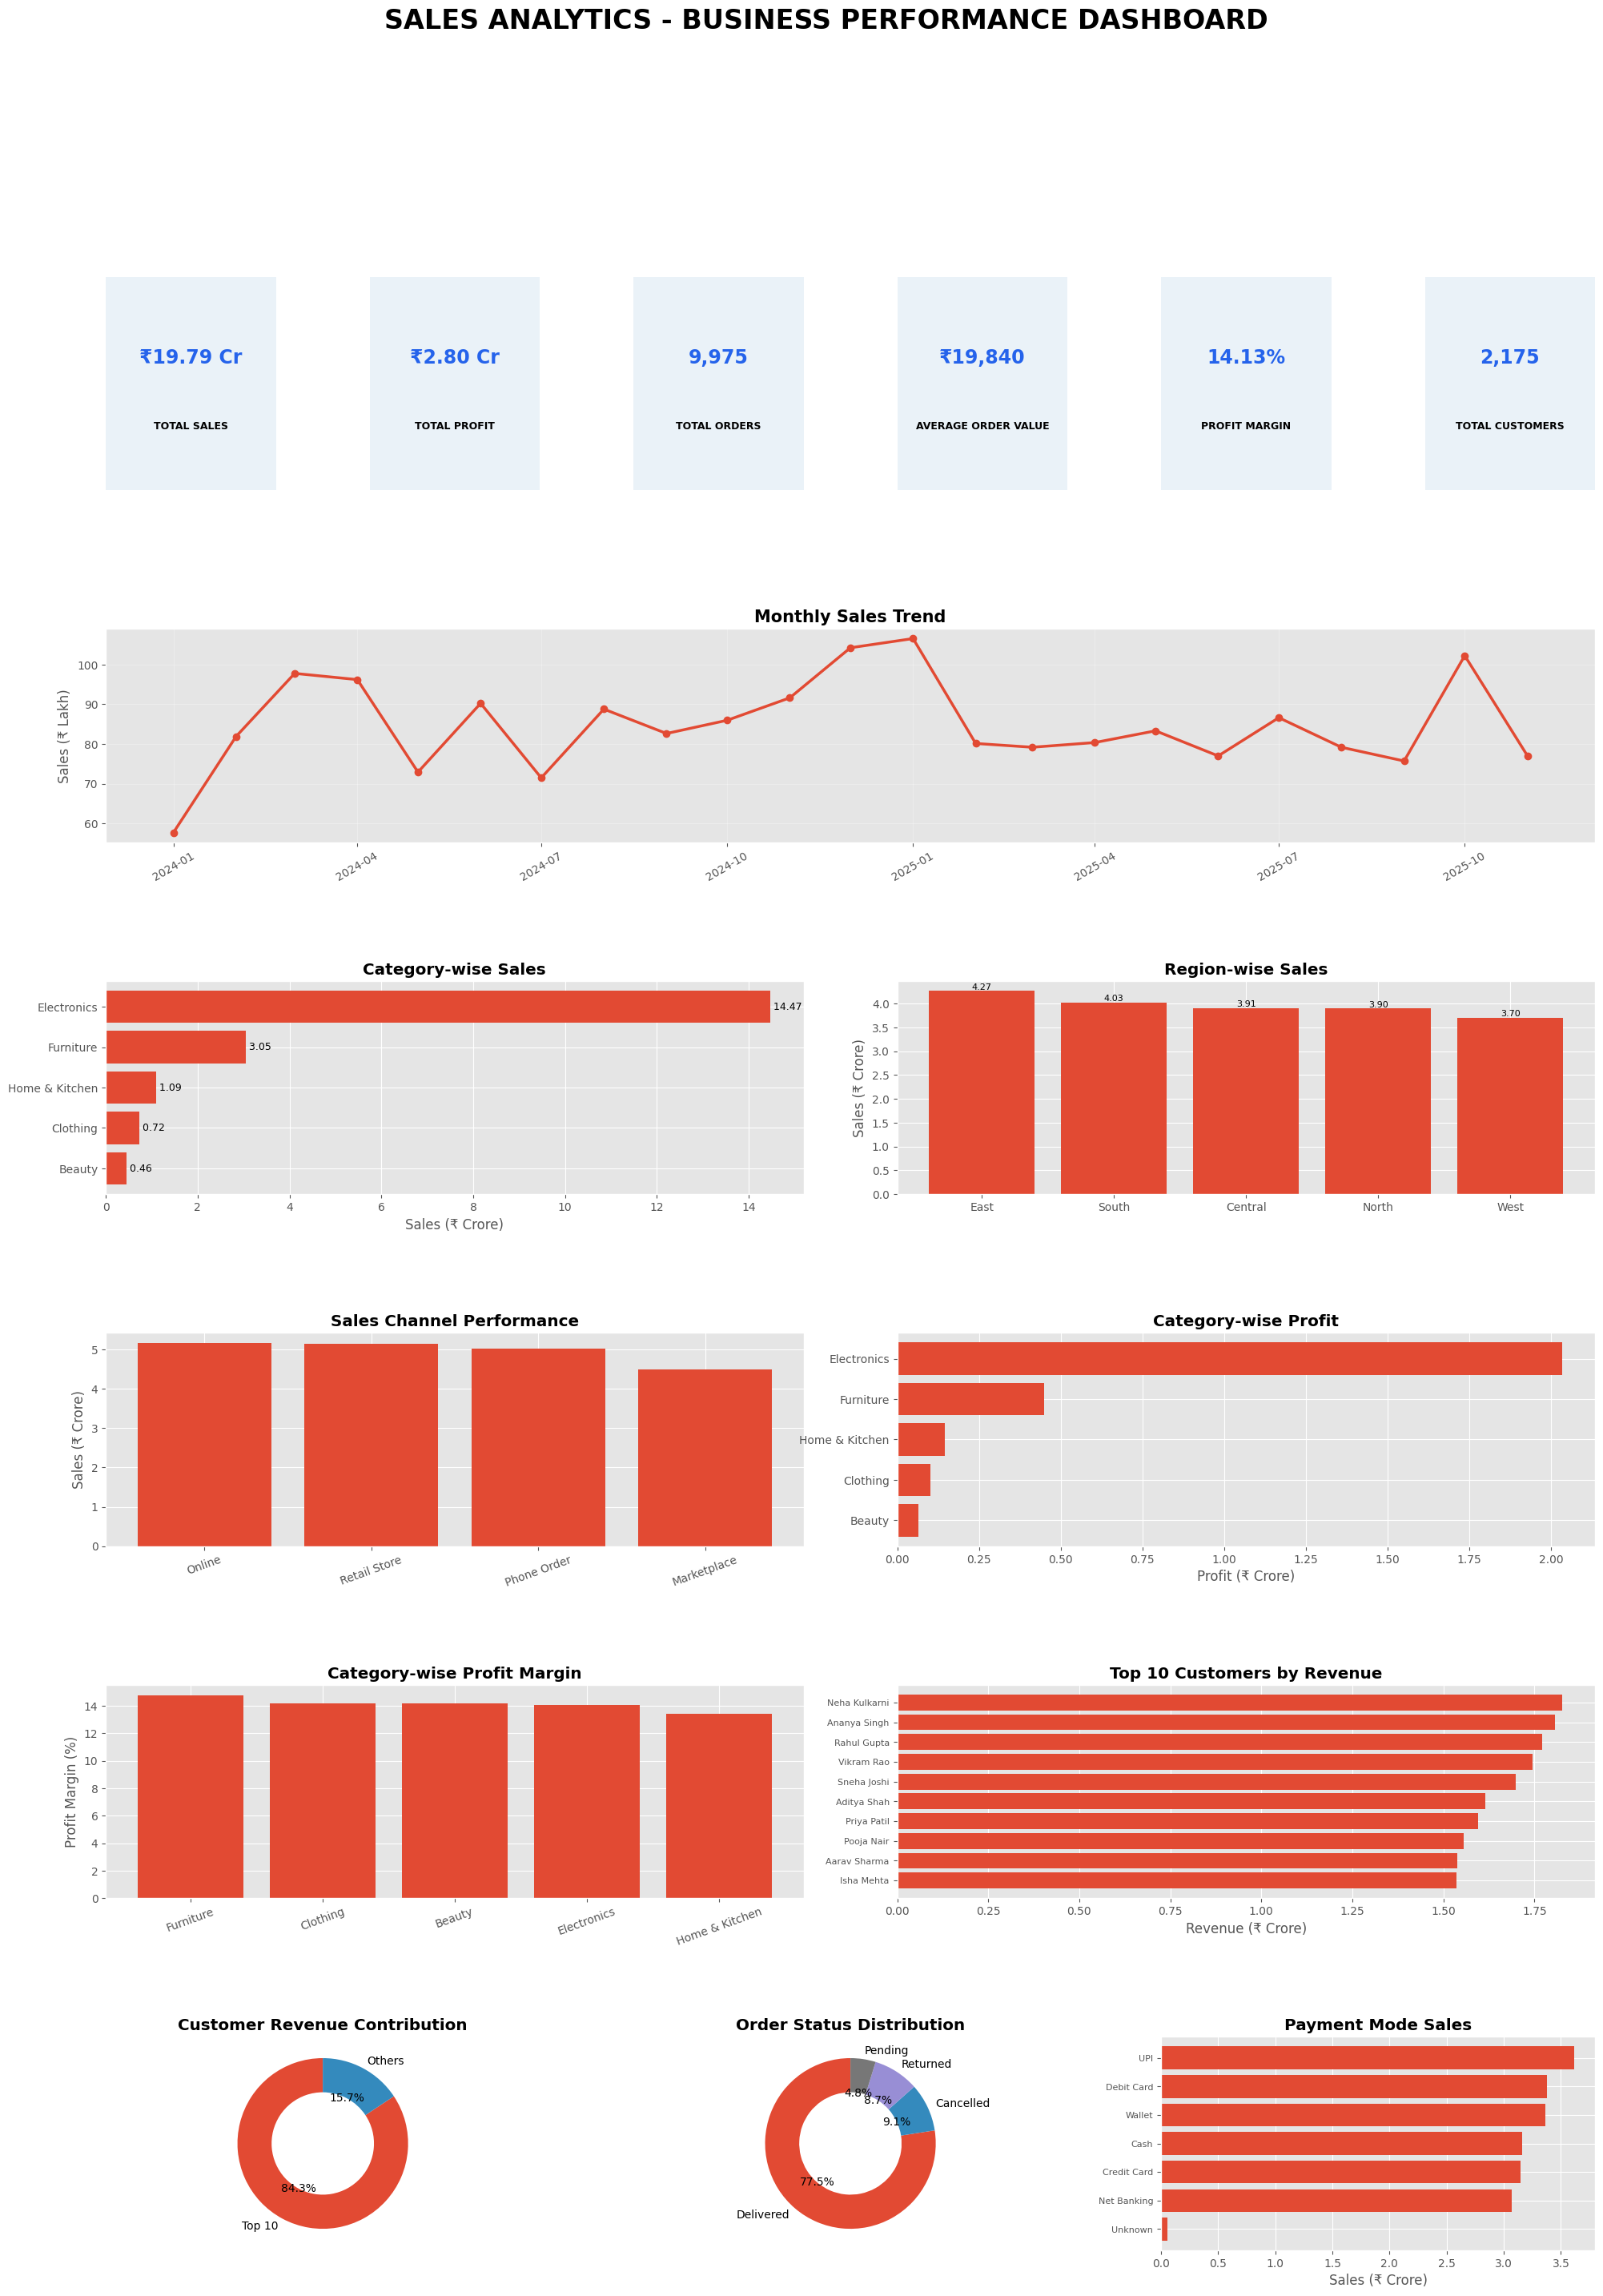

In [42]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.gridspec as gridspec
import numpy as np

# Dashboard Setup
fig = plt.figure(figsize=(24, 32))

gs = gridspec.GridSpec(
    6, 6,
    figure=fig,
    hspace=0.65,
    wspace=0.55
)

fig.suptitle(
    "SALES ANALYTICS - BUSINESS PERFORMANCE DASHBOARD",
    fontsize=24,
    fontweight="bold",
    y=0.985
)

# --------------------------------
# 1. KPI CARDS
# --------------------------------

kpis = [
    ("TOTAL SALES", f"₹{total_sales/10000000:.2f} Cr"),
    ("TOTAL PROFIT", f"₹{total_profit/10000000:.2f} Cr"),
    ("TOTAL ORDERS", f"{total_orders:,}"),
    ("AVERAGE ORDER VALUE", f"₹{average_order_value:,.0f}"),
    ("PROFIT MARGIN", f"{profit_margin:.2f}%"),
    ("TOTAL CUSTOMERS", f"{total_customers:,}")
]

for i, (title, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])

    ax.set_facecolor("#EAF2F8")
    ax.text(
        0.5, 0.62, value,
        ha="center", va="center",
        fontsize=17, fontweight="bold",
        color="#2563EB"
    )
    ax.text(
        0.5, 0.30, title,
        ha="center", va="center",
        fontsize=9, fontweight="bold"
    )
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


# --------------------------------
# 2. MONTHLY SALES TREND
# --------------------------------

ax1 = fig.add_subplot(gs[1, :])

ax1.plot(
    monthly_sales.index,
    monthly_sales.values / 100000,
    marker="o",
    linewidth=2.5
)

ax1.set_title("Monthly Sales Trend", fontweight="bold", fontsize=15)
ax1.set_ylabel("Sales (₹ Lakh)")
ax1.tick_params(axis="x", rotation=30)
ax1.grid(alpha=0.3)


# --------------------------------
# 3. CATEGORY-WISE SALES
# --------------------------------

ax2 = fig.add_subplot(gs[2, :3])

bars = ax2.barh(
    category_sales.index,
    category_sales.values / 10000000
)

ax2.invert_yaxis()
ax2.set_title("Category-wise Sales", fontweight="bold")
ax2.set_xlabel("Sales (₹ Crore)")

for bar in bars:
    w = bar.get_width()
    ax2.text(w, bar.get_y() + bar.get_height()/2,
             f" {w:.2f}", va="center", fontsize=9)


# --------------------------------
# 4. REGION-WISE SALES
# --------------------------------

ax3 = fig.add_subplot(gs[2, 3:])

bars = ax3.bar(
    region_sales.index,
    region_sales.values / 10000000
)

ax3.set_title("Region-wise Sales", fontweight="bold")
ax3.set_ylabel("Sales (₹ Crore)")

for bar in bars:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2,
             h, f"{h:.2f}",
             ha="center", va="bottom", fontsize=8)


# --------------------------------
# 5. SALES CHANNEL
# --------------------------------

ax4 = fig.add_subplot(gs[3, :3])

ax4.bar(
    channel_sales.index,
    channel_sales.values / 10000000
)

ax4.set_title("Sales Channel Performance", fontweight="bold")
ax4.set_ylabel("Sales (₹ Crore)")
ax4.tick_params(axis="x", rotation=20)


# --------------------------------
# 6. CATEGORY-WISE PROFIT
# --------------------------------

ax5 = fig.add_subplot(gs[3, 3:])

ax5.barh(
    category_profit.index,
    category_profit.values / 10000000
)

ax5.invert_yaxis()
ax5.set_title("Category-wise Profit", fontweight="bold")
ax5.set_xlabel("Profit (₹ Crore)")


# --------------------------------
# 7. PROFIT MARGIN
# --------------------------------

ax6 = fig.add_subplot(gs[4, :3])

ax6.bar(
    category_margin.index,
    category_margin["Profit_Margin_%"]
)

ax6.set_title("Category-wise Profit Margin", fontweight="bold")
ax6.set_ylabel("Profit Margin (%)")
ax6.tick_params(axis="x", rotation=20)


# --------------------------------
# 8. TOP 10 CUSTOMERS
# --------------------------------

ax7 = fig.add_subplot(gs[4, 3:])

ax7.barh(
    top_customers.index,
    top_customers.values / 10000000
)

ax7.invert_yaxis()
ax7.set_title("Top 10 Customers by Revenue", fontweight="bold")
ax7.set_xlabel("Revenue (₹ Crore)")
ax7.tick_params(axis="y", labelsize=8)


# --------------------------------
# 9. CUSTOMER CONTRIBUTION
# --------------------------------

ax8 = fig.add_subplot(gs[5, :2])

other_customers_sales = total_sales - top_10_sales

ax8.pie(
    [top_10_sales, other_customers_sales],
    labels=["Top 10", "Others"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

ax8.set_title("Customer Revenue Contribution", fontweight="bold")


# --------------------------------
# 10. ORDER STATUS
# --------------------------------

ax9 = fig.add_subplot(gs[5, 2:4])

ax9.pie(
    order_status.values,
    labels=order_status.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

ax9.set_title("Order Status Distribution", fontweight="bold")


# --------------------------------
# 11. PAYMENT MODE SALES
# --------------------------------

ax10 = fig.add_subplot(gs[5, 4:])

ax10.barh(
    payment_sales.index,
    payment_sales.values / 10000000
)

ax10.invert_yaxis()
ax10.set_title("Payment Mode Sales", fontweight="bold")
ax10.set_xlabel("Sales (₹ Crore)")
ax10.tick_params(axis="y", labelsize=8)


# --------------------------------
# FINAL DISPLAY
# --------------------------------

plt.savefig(
    "Sales_Analytics_Complete_Dashboard.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [43]:
import matplotlib.pyplot as plt

print("Open figures:", plt.get_fignums())

Open figures: []


In [44]:
%whos

Variable                  Type            Data/Info
---------------------------------------------------
average_order_value       float64         19840.01337944862
ax                        Axes            Axes(0.811429,0.796757;0.0885714x0.0832432)
ax1                       Axes            Axes(0.125,0.659405;0.775x0.0832432)
ax10                      Axes            Axes(0.674143,0.11;0.225857x0.0832432)
ax2                       Axes            Axes(0.125,0.522054;0.363143x0.0832432)
ax3                       Axes            Axes(0.536857,0.522054;0.363143x0.0832432)
ax4                       Axes            Axes(0.125,0.384703;0.363143x0.0832432)
ax5                       Axes            Axes(0.536857,0.384703;0.363143x0.0832432)
ax6                       Axes            Axes(0.125,0.247351;0.363143x0.0832432)
ax7                       Axes            Axes(0.536857,0.247351;0.363143x0.0832432)
ax8                       Axes            Axes(0.182433,0.11;0.110991x0.0832432)
ax9     

In [47]:
fig.savefig(
    "Sales_Analytics_Visuals.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "Sales_Analytics_Visuals.pdf",
    bbox_inches="tight"
)